# Verification — Lipniacki et al. (2008) TCR signaling: both steady-state branches over N_agonist = 1 to 1000

This notebook checks the steady states of `tcr_signaling_bistability_lipniacki2008.bngl`
over a 20-point logarithmic grid of the number of agonist pMHC per cell,
N_agonist = 10^(3k/19), k = 0..19 (1 to 1000). `verify_lipniacki2008.ipynb` is the entry
point for the folder; it checks one trajectory, at N_agonist = 30, which ends on the ERK-high
branch. Here both stable branches are checked wherever they exist.

**The source figure is Fig. 7A.** Its caption in the NIH author manuscript (PMC2577002,
NIHMS68204) reads: "Steady states for three different values of peptide dissociation rate
constant d = 0.1/s, 0.05/s, 0.0333/s. Stable steady states for ppERK are plotted as a function
of log(N), where N is the number of peptide-MHC per cell. The unstable states connecting
saddle-node bifurcation points are not shown." This file's agonist dissociation rate constant
is d1 = 0.05/s, the blue curves. They are digitized by `digitize_lipniacki2008.py` from the
manuscript's figure bitmap, the only copy that could be obtained (see that script).

Two protocols are run at every dose, with BNG2.pl and with the independent equations:

* **primed** — the file as distributed, with only `N_agonist` changed: the ligand-free primed
  cell of the Fig. 7B protocol is given N agonist pMHC. A primed cell switches to the ERK-high
  branch wherever that branch exists.
* **ramp** — a cell that is already at steady state receives more agonist: starting from the
  primed cell at N = 1, each dose adds the difference to the free agonist pool
  (BNG2.pl `addConcentration`) and runs to steady state again. Such a cell stays on the
  ERK-low branch until that branch ends.

| | check | reference | tolerance |
|---|---|---|---|
| (a) | species mapping: all 37 species of the committed deterministic trajectory (`reference/..._ode.cdat`, N = 30) | the independent equations integrated over the same 3 h | max rel err 1e-6 |
| (b) | independent steady states: a root of the equations, stable, on the continuation curve | residual and Jacobian | max \|dy/dt\| <= 1e-6 molecules/s; all eigenvalues < 0 |
| (c) | BNG2.pl final state, all 37 species, both protocols, 20 doses | the independent steady state reached by the same protocol | max rel err 1e-6 (floor 1 molecule) |
| (d) | which branch each protocol reaches | the folds of the independent continuation | primed: high iff N > lower fold; ramp: low iff N < upper fold; the two differ at exactly the bistable doses |
| (e) | every BNG2.pl run has converged | its own last two outputs | change <= 10 (rtol \|x\| + atol) |
| (f) | level 2: BNG2.pl ppERK on both branches at the doses the digitized curves cover | Fig. 7A, d = 0.05/s | max \|log10 ratio\| 0.024 decade (2 px) |
| (g) | level 2: where the published branches end | the folds | within half a stroke + 1 px (0.056 decade) |

**Why these tolerances.** (a)-(c): the independent equations are written from the paper's
Appendix A and do not read BioNetGen's network; both sides integrate with rtol = atol = 1e-10
and the steady states are polished by Newton's method, so 1e-6 (relative, with a floor of one
molecule, as in the entry-point notebook) leaves ample room for solver error while being far
smaller than any difference between branches. (f): on the ppERK axis one pixel is 0.0118
decade (84.5 px per decade); two pixels cover locating the centre of a 4-pixel JPEG stroke
(+/- 1 px), the calibration residual (0.36 px) and half a pixel of abscissa times the curve's
slope. (g): where a branch ends at a fold its tangent is vertical, so the curve's end lies half
a stroke width (2 px) inside the end of the ink; the cap shape is unknown, so the allowance is
half a stroke plus one pixel, 3 px of 53.9 per decade.

**How BNG2.pl is run.** Temporary copies of the primary file keep the model block byte for
byte, except the `N_agonist` value, and replace the actions block. Primed: one copy per dose,
`generate_network` and one `simulate` to t = 2e6 s. Ramp: one copy at N = 1, `simulate`, then
per dose `addConcentration("pMHC(p~ag)", dN)` and `simulate` again. Every run uses
rtol = atol = 1e-10 and 20 output intervals. Set `BNGPATH` to a BioNetGen 2.9.3 directory.
Nothing here uses any simulator other than BNG2.pl and its `run_network`.

**Plot convention:** lines = BioNetGen; open markers = independent steady states; squares =
digitized Fig. 7A.

In [1]:
import json
import os
import re
import subprocess
import sys
import tempfile
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.integrate import solve_ivp

matplotlib.rcParams["figure.dpi"] = 100

STEM = "tcr_signaling_bistability_lipniacki2008"


def find_model_dir():
    for c in (Path.cwd(), Path.cwd() / "models" / STEM):
        if (c / f"{STEM}.bngl").exists():
            return c.resolve()
    raise FileNotFoundError(f"run this notebook from models/{STEM}/")


MODEL_DIR = find_model_dir()
os.chdir(MODEL_DIR)
REF = Path("reference")
sys.path.insert(0, ".")
sys.path.insert(0, "../../skills/curate-model/scripts")
from verification_figure import Comparison, residual_axis, summarize, verdict_footer  # noqa: E402

BNG2 = Path(os.path.expanduser(os.environ.get("BNGPATH", "~/Simulations/BioNetGen-2.9.3"))) / "BNG2.pl"
assert BNG2.is_file(), "set BNGPATH to a BioNetGen 2.9.3 directory"

TOL_SS = 1e-6             # (a), (c): relative, floor one molecule
TOL_RESID = 1e-6          # (b): molecules/s
TOL_CONVERGED = 10.0      # (e): in units of rtol*|x| + atol
RTOL = ATOL = 1e-10       # every integration here, BNG2.pl and SciPy
PX_PER_DECADE_Y, PX_PER_DECADE_X = 84.54, 53.87   # the digitizer's calibration of Fig. 7A
TOL_FIG = 2 / PX_PER_DECADE_Y        # (f): 0.024 decade
T_END, N_STEPS = 2e6, 20
DOSES = 10 ** (3 * np.arange(20) / 19)

## The independent equations

`independent_lipniacki2008.py` holds the 37-state right-hand side of the entry-point notebook.
The cell below checks that its code block is still byte-identical to that notebook's cell.

In [2]:
import independent_lipniacki2008 as ind  # noqa: E402

cell = next("".join(c["source"]) for c in json.loads(Path("verify_lipniacki2008.ipynb").read_text())["cells"]
            if c["cell_type"] == "code" and "def rhs(" in "".join(c["source"]))
block = cell[cell.index("p = {"):cell.index("\n\n\ny0 = np.zeros(37)")]
module_text = Path("independent_lipniacki2008.py").read_text()
copied = module_text.split("# --- begin: copied verbatim from verify_lipniacki2008.ipynb ---\n")[1]
copied = copied.split("\n# --- end: copied verbatim from verify_lipniacki2008.ipynb ---")[0]
assert copied == block, "independent_lipniacki2008.py no longer matches verify_lipniacki2008.ipynb"
print(f"independent_lipniacki2008.py == the rhs cell of verify_lipniacki2008.ipynb "
      f"({block.count(chr(10)) + 1} lines)")
rhs = ind.rhs

# Conservation laws: the eight pools of the entry-point notebook (rows), in y1..y37 numbering.
POOLS = {
    "agonist": [1, *range(2, 11), 23, 24],
    "antagonist": [11, *range(12, 21), 25, 26],
    "TCR": [*range(2, 11), *range(12, 27)],
    "LCK": [*range(3, 11), *range(13, 21), 24, 26, 27],
    "SHP1": [22, 23, 24, 25, 26, 28, 29],
    "ZAP70": [30, 31],
    "MEK": [32, 33, 34],
    "ERK": [35, 36, 37],
}
C = np.zeros((8, 37))
for i, members in enumerate(POOLS.values()):
    C[i, [m - 1 for m in members]] = 1.0
assert np.linalg.matrix_rank(C) == 8
Z = np.linalg.svd(C)[2][8:].T          # orthonormal basis of the directions conserving all pools
DROP = [0, 10, 20, 26, 27, 29, 31, 34]  # one equation per pool, replaced by its conservation law
KEEP = [i for i in range(37) if i not in DROP]
assert np.allclose(C[:, DROP], np.eye(8))


def primed_state(n):
    """The file's seed state with N_agonist = n, in y1..y37 order."""
    y = np.zeros(37)
    y[[0, 20, 21, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36]] = [
        n, 25603, 4397, 100000, 295082, 521, 99990, 10, 97561, 2379, 60, 285833, 13498, 669]
    return y


def jac_fd(fun, y):
    J = np.zeros((len(fun(y)), len(y)))
    for j in range(len(y)):
        h = 1e-7 * max(1.0, abs(y[j]))
        yp, ym = y.copy(), y.copy()
        yp[j] += h
        ym[j] -= h
        J[:, j] = (fun(yp) - fun(ym)) / (2 * h)
    return J


def newton_polish(y, tot):
    """Newton on the 29 independent rate equations plus the 8 conservation laws."""
    def G(z):
        return np.concatenate([rhs(0, z)[KEEP], C @ z - tot])
    for _ in range(30):
        step = np.linalg.solve(jac_fd(G, y), -G(y))
        y = y + step
        if np.max(np.abs(step) / np.maximum(np.abs(y), 1.0)) < 1e-13:
            return y
    raise RuntimeError("Newton did not converge")


def max_growth(y):
    """Largest real part of the Jacobian's eigenvalues on the conservation manifold."""
    return np.linalg.eigvals(Z.T @ jac_fd(lambda z: rhs(0, z), y) @ Z).real.max()

independent_lipniacki2008.py == the rhs cell of verify_lipniacki2008.ipynb (115 lines)


## (a) Species mapping, checked on the committed trajectory

The BNG2.pl species are matched to y1..y37 from their BNGL strings alone: which pMHC (if
any) is bound, the ITAM state, whether LCK is bound and in which (Y, S59) state, and whether
SHP1 is bound. The mapping must be a bijection, and it must reproduce the committed
deterministic trajectory at N = 30 (`reference/..._ode.cdat`, all 37 species, 3 h).

In [3]:
def parse(species):
    mols = {}
    for m in species.split("."):
        name, comps = re.match(r"(\w+)\((.*)\)", m).groups()
        mols[name] = {c.split("~")[0].split("!")[0]: (c.split("~")[1].split("!")[0] if "~" in c else None,
                                                     "!" in c)
                      for c in comps.split(",") if c}
    return mols


def y_index(species):
    m = parse(species)
    if "TCR" not in m:
        (name, comps), = m.items()
        state = next(iter(comps.values()))[0]
        free = {("pMHC", "ag"): 1, ("pMHC", "en"): 11, ("LCK", None): 27, ("SHP1", "u"): 28,
                ("SHP1", "p"): 29, ("ZAP70", "u"): 30, ("ZAP70", "p"): 31, ("MEK", "u"): 32,
                ("MEK", "p"): 33, ("MEK", "pp"): 34, ("ERK", "u"): 35, ("ERK", "p"): 36,
                ("ERK", "pp"): 37}
        if name == "LCK":
            assert comps["y"][0] == "u" and comps["s"][0] == "u"
            return 27
        return free[(name, comps["y" if name in ("SHP1", "ZAP70") else ("p" if name == "pMHC" else "s")][0])]
    itam = m["TCR"]["itam"][0]
    lck = (m["LCK"]["y"][0], m["LCK"]["s"][0]) if "LCK" in m else None
    shp = "SHP1" in m
    if "pMHC" not in m:
        assert lck is None and itam == "u"
        return 22 if shp else 21
    base = 0 if m["pMHC"]["p"][0] == "ag" else 10
    if shp:
        assert itam == "u" and lck in (None, ("u", "u"))
        return (23 if lck is None else 24) + (0 if base == 0 else 2)
    order = {None: 2, ("u", "u"): 3, ("u", "p"): 4}
    if lck in order:
        assert itam == "u"
        return base + order[lck]
    k = {"u": 0, "p": 2, "pp": 4}[itam] + (0 if lck == ("p", "u") else 1)
    return base + 5 + k


def net_species(path):
    block = re.search(r"begin species(.*?)end species", Path(path).read_text(), re.S).group(1)
    return [ln.split()[1] for ln in block.strip().splitlines()]


SPECIES = net_species(REF / f"{STEM}.net")
PERM = [y_index(s) - 1 for s in SPECIES]       # .net species j  ->  y index PERM[j]
assert sorted(PERM) == list(range(37)), "species mapping is not a bijection"
assert net_species(REF / f"{STEM}_ode.net") == SPECIES


def to_y(cdat_row):
    y = np.zeros(37)
    y[PERM] = cdat_row
    return y


ode = np.loadtxt(REF / f"{STEM}_ode.cdat")
t_ref = ode[:, 0]
sol = solve_ivp(rhs, (0, t_ref[-1]), to_y(ode[0, 1:]), t_eval=t_ref, method="LSODA",
                rtol=RTOL, atol=ATOL)
assert sol.success
assert np.allclose(to_y(ode[0, 1:]), primed_state(30))
bng_y = np.array([to_y(r) for r in ode[:, 1:]])
err_a = np.abs(bng_y - sol.y.T) / np.maximum(np.abs(sol.y.T), 1.0)
print(f"(a) committed N = 30 trajectory, 37 species x {len(t_ref)} times: max rel err "
      f"{err_a.max():.2e} (tol {TOL_SS:g})")
assert err_a.max() <= TOL_SS

(a) committed N = 30 trajectory, 37 species x 601 times: max rel err 4.18e-09 (tol 1e-06)


## The independent bifurcation diagram

Pseudo-arclength continuation of the 37 equations (29 rate equations and 8 conservation laws)
in log10 N, from the low steady state at N = 1 through both folds to N = 2000. The folds are
located by bisection on the sign of dlog10(N)/ds along the curve; stability is read from the
Jacobian on the conservation manifold.

In [4]:
TOT = C @ primed_state(0.0)
SC = 1e5


def H(x):
    y, s = x[:37] * SC, x[37]
    tot = TOT.copy()
    tot[0] = 10**s
    return np.concatenate([rhs(0, y)[KEEP] / SC, (C @ y - tot) / SC])


def JH(x):
    J = np.zeros((37, 38))
    for j in range(38):
        h = 1e-8 * max(1.0, abs(x[j])) if j < 37 else 1e-7
        xp, xm = x.copy(), x.copy()
        xp[j] += h
        xm[j] -= h
        J[:, j] = (H(xp) - H(xm)) / (2 * h)
    return J


def tangent(J, prev):
    t = np.linalg.svd(J)[2][-1]
    t = t if t @ prev >= 0 else -t
    return t / np.linalg.norm(t)


def correct(x0, t, ds):
    x = x0 + ds * t
    for it in range(30):
        dx = np.linalg.solve(np.vstack([JH(x), t]), -np.concatenate([H(x), [t @ (x - x0) - ds]]))
        x = x + dx
        if np.max(np.abs(dx)) < 1e-13:
            return x, it
    return None, it


s0 = solve_ivp(rhs, (0, T_END), primed_state(1.0), method="LSODA", rtol=RTOL, atol=ATOL)
x = np.concatenate([newton_polish(s0.y[:, -1], C @ primed_state(1.0)) / SC, [0.0]])
t = tangent(JH(x), np.eye(38)[37])
curve, turns, ds = [x], [], 0.02
while x[37] < np.log10(2000):
    xn, it = correct(x, t, ds)
    if xn is None:
        ds /= 2
        assert ds > 1e-9
        continue
    tn = tangent(JH(xn), t)
    if np.sign(tn[37]) != np.sign(t[37]):
        turns.append((x, t, np.linalg.norm(xn - x), len(curve) - 1))
    x, t = xn, tn
    curve.append(x)
    ds = min(ds * 1.3, 0.05) if it < 4 else ds
curve = np.array(curve)
assert len(turns) == 2, f"expected two folds, found {len(turns)}"

folds = []
for xa, ta, span, _ in turns:
    lo, hi = 0.0, span
    for _ in range(50):
        mid = 0.5 * (lo + hi)
        xm, _ = correct(xa, ta, mid)
        lo, hi = (mid, hi) if np.sign(tangent(JH(xm), ta)[37]) == np.sign(ta[37]) else (lo, mid)
    folds.append((10 ** xm[37], xm[36] * SC))
(N_HI, ERK_HI), (N_LO, ERK_LO) = folds    # the curve meets the upper fold first
assert N_LO < N_HI
c_N, c_erk = 10 ** curve[:, 37], curve[:, 36] * SC
c_growth = np.array([max_growth(c[:37] * SC) for c in curve])
print(f"{len(curve)} continuation points; folds at N = {N_LO:.6f} (ppERK {ERK_LO:.1f}) and "
      f"N = {N_HI:.4f} (ppERK {ERK_HI:.1f})")
middle = slice(turns[0][3] + 2, turns[1][3])     # strictly between the two folds
outer = np.r_[0:turns[0][3] - 1, turns[1][3] + 2:len(curve)]
assert np.all(c_growth[middle] > 0) and np.all(c_growth[outer] < 0)
print(f"bistable for {N_LO:.4f} < N < {N_HI:.2f}; the middle branch is unstable (growth rate "
      f"{c_growth[middle].min():.2e} to {c_growth[middle].max():.2e} /s), the outer branches stable")
bistable = (DOSES > N_LO) & (DOSES < N_HI)
print(f"{bistable.sum()} of {len(DOSES)} doses are bistable: N = {DOSES[bistable][0]:.4g} .. "
      f"{DOSES[bistable][-1]:.4g}")

196 continuation points; folds at N = 8.845187 (ppERK 120168.6) and N = 772.1141 (ppERK 3735.4)
bistable for 8.8452 < N < 772.11; the middle branch is unstable (growth rate 9.56e-05 to 2.56e-03 /s), the outer branches stable
13 of 20 doses are bistable: N = 8.859 .. 695.2


## (b) Independent steady states, both protocols

In [5]:
def settle(y0):
    tot = C @ y0
    s = solve_ivp(rhs, (0, T_END), y0, method="LSODA", rtol=RTOL, atol=ATOL)
    assert s.success
    y = newton_polish(s.y[:, -1], tot)
    resid = np.max(np.abs(rhs(0, y)))
    return y, resid, max_growth(y)


ref, resid, growth = {"primed": [], "ramp": []}, [], []
for n in DOSES:
    y, r, g = settle(primed_state(n))
    ref["primed"].append(y)
    resid.append(r)
    growth.append(g)
y = None
for k, n in enumerate(DOSES):
    start = primed_state(n) if k == 0 else ref["ramp"][-1] + np.eye(37)[0] * (n - DOSES[k - 1])
    y, r, g = settle(start)
    ref["ramp"].append(y)
    resid.append(r)
    growth.append(g)
ref = {k: np.array(v) for k, v in ref.items()}
print(f"(b) 40 independent steady states: max |dy/dt| {max(resid):.1e} molecules/s "
      f"(tol {TOL_RESID:g}); largest eigenvalue real part {max(growth):.2e} /s (all < 0)")
assert max(resid) <= TOL_RESID and max(growth) < 0
AGONIST = [m - 1 for m in POOLS["agonist"]]
for proto in ref:
    assert np.allclose(ref[proto][:, AGONIST].sum(1), DOSES, rtol=1e-12)


def branch_of(erk):
    """'high' or 'low', by which side of the middle branch ppERK lies on at that dose."""
    return np.where(erk > 50_000, "high", "low")


for proto in ref:
    print(f"  {proto:>6}: " + " ".join(f"{b[0]}" for b in branch_of(ref[proto][:, 36])))

(b) 40 independent steady states: max |dy/dt| 9.1e-13 molecules/s (tol 1e-06); largest eigenvalue real part -6.64e-05 /s (all < 0)
  primed: l l l l l l h h h h h h h h h h h h h h
    ramp: l l l l l l l l l l l l l l l l l l l h


## (c)-(e) BNG2.pl steady states, both protocols

In [6]:
model_text = Path(f"{STEM}.bngl").read_text()
head, sep, _ = model_text.rpartition("end model")
assert sep and "begin actions" not in head
N_LINE = re.compile(r"^(  N_agonist\s+)30(\s+# molecules/cell)$", re.M)
assert len(N_LINE.findall(head)) == 1
sim = (f'simulate({{method=>"ode",t_start=>0,t_end=>{T_END:g},n_steps=>{N_STEPS},'
       f'atol=>{ATOL:g},rtol=>{RTOL:g},suffix=>"%s"}})')


def copy_at(n, actions):
    body = N_LINE.sub(lambda m: f"{m.group(1)}{float(n)!r}{m.group(2)}", head)
    return body + sep + "\n\nbegin actions\n" + "".join(f"  {a}\n" for a in actions) + "end actions\n"


def run_bng(text, stem, workdir):
    (workdir / f"{stem}.bngl").write_text(text)
    r = subprocess.run(["perl", str(BNG2), f"{stem}.bngl"], cwd=workdir, capture_output=True,
                       text=True, timeout=1800)
    assert r.returncode == 0, r.stdout[-3000:] + r.stderr[-3000:]
    assert net_species(workdir / f"{stem}.net") == SPECIES


def read_run(prefix):
    cdat = np.loadtxt(f"{prefix}.cdat")
    assert np.isclose(cdat[-1, 0], T_END)
    change = np.max(np.abs(cdat[-1, 1:] - cdat[-2, 1:]) / (RTOL * np.abs(cdat[-1, 1:]) + ATOL))
    return to_y(cdat[0, 1:]), to_y(cdat[-1, 1:]), change


bng, starts, changes = {"primed": [], "ramp": []}, {"primed": [], "ramp": []}, []
with tempfile.TemporaryDirectory(prefix="lipniacki2008_ss_") as tmp:
    tmp = Path(tmp)
    for k, n in enumerate(DOSES):
        stem = f"{STEM}_primed{k:02d}"
        run_bng(copy_at(n, ["generate_network({overwrite=>1})", sim % "ss"]), stem, tmp)
        y0, y1, ch = read_run(tmp / f"{stem}_ss")
        starts["primed"].append(y0)
        bng["primed"].append(y1)
        changes.append(ch)
    actions = ["generate_network({overwrite=>1})", sim % "ramp00"]
    for k in range(1, len(DOSES)):
        actions += [f'addConcentration("pMHC(p~ag)",{float(DOSES[k] - DOSES[k - 1])!r})',
                    sim % f"ramp{k:02d}"]
    stem = f"{STEM}_ramp"
    run_bng(copy_at(DOSES[0], actions), stem, tmp)
    for k in range(len(DOSES)):
        y0, y1, ch = read_run(tmp / f"{stem}_ramp{k:02d}")
        starts["ramp"].append(y0)
        bng["ramp"].append(y1)
        changes.append(ch)
bng = {k: np.array(v) for k, v in bng.items()}
starts = {k: np.array(v) for k, v in starts.items()}
changes = np.array(changes)

# Every start must hold N agonist pMHC. A primed start is the file's seed state exactly; a ramp
# start inherits the previous run's final state, so its pool carries that run's integration
# error (CVODE conserves the pools only to its tolerances) and the 13 printed digits.
assert np.allclose(starts["primed"], [primed_state(n) for n in DOSES], rtol=1e-12)
pool_dev = {p: np.max(np.abs(starts[p][:, AGONIST].sum(1) - DOSES) / DOSES) for p in bng}
print(f"{2 * len(DOSES)} BNG2.pl runs; agonist pool at the start vs N: max rel deviation "
      f"primed {pool_dev['primed']:.1e}, ramp {pool_dev['ramp']:.1e}")
assert max(pool_dev.values()) <= 1e-8

# (e) converged
print(f"(e) last-two-output change {changes.max():.2f} x (rtol |x| + atol) (tol {TOL_CONVERGED:g} x)")
assert changes.max() <= TOL_CONVERGED

# (c) BNG2.pl vs the independent steady state of the same protocol
err_c = {p: np.abs(bng[p] - ref[p]) / np.maximum(np.abs(ref[p]), 1.0) for p in bng}
for p in bng:
    print(f"(c) {p:>6}: all 37 species at 20 doses, max rel err {err_c[p].max():.2e} (tol {TOL_SS:g})")
    assert err_c[p].max() <= TOL_SS

# (d) branches
br = {p: branch_of(bng[p][:, 36]) for p in bng}
assert np.array_equal(br["primed"] == "high", DOSES > N_LO)
assert np.array_equal(br["ramp"] == "low", DOSES < N_HI)
assert np.array_equal(br["primed"] != br["ramp"], bistable)
print(f"(d) primed reaches the high branch exactly where N > {N_LO:.4f}; the ramp stays low "
      f"exactly where N < {N_HI:.2f}; they differ at exactly the {bistable.sum()} bistable doses")

print(f"\n{'N':>9} {'primed ppERK':>13} {'ramp ppERK':>11} {'primed pSHP1':>13} {'ramp pSHP1':>11} "
      f"{'rel err':>8}")
pshp = [m - 1 for m in (22, 23, 24, 25, 26, 29)]
for k, n in enumerate(DOSES):
    print(f"{n:9.4g} {bng['primed'][k, 36]:13.1f} {bng['ramp'][k, 36]:11.1f} "
          f"{bng['primed'][k, pshp].sum():13.1f} {bng['ramp'][k, pshp].sum():11.1f} "
          f"{max(err_c['primed'][k].max(), err_c['ramp'][k].max()):8.1e}")

40 BNG2.pl runs; agonist pool at the start vs N: max rel deviation primed 2.8e-13, ramp 6.9e-10
(e) last-two-output change 0.55 x (rtol |x| + atol) (tol 10 x)
(c) primed: all 37 species at 20 doses, max rel err 6.70e-10 (tol 1e-06)
(c)   ramp: all 37 species at 20 doses, max rel err 7.90e-10 (tol 1e-06)
(d) primed reaches the high branch exactly where N > 8.8452; the ramp stays low exactly where N < 772.11; they differ at exactly the 13 bistable doses

        N  primed ppERK  ramp ppERK  primed pSHP1  ramp pSHP1  rel err
        1        6708.7      6708.7       18023.1     18023.1  5.0e-10
    1.438        7323.3      7323.3       20643.5     20643.5  3.8e-10
    2.069        7374.2      7374.2       23359.2     23359.2  7.9e-10
    2.976        6897.6      6897.6       26109.7     26109.7  7.5e-10
    4.281        6115.1      6115.1       28860.0     28860.0  2.2e-10
    6.158        5267.5      5267.5       31604.2     31604.2  2.5e-10
    8.859      123480.1      4500.1       3108

## (f), (g) Level 2: Fig. 7A

The digitized curves are interpolated onto each dose (linearly in log-log, between the two
adjacent pixel columns, which must both be unflagged) and compared with BNG2.pl's steady state
on the same branch: the high branch from the primed protocol and the low branch from the
ramp. Doses outside a curve's unflagged extent are not compared. Over N > 40 the published
ERK-high curve for d = 0.05/s lies under the d = 0.0333/s curve, so it is flagged as occluded
there and the high branch is compared over N = 10.5 to 39 only.

In [7]:
dig_path = REF / "lipniacki2008_fig7a_d0p05_ppERK_steady_states_digitized.csv"
dig = pd.read_csv(dig_path, comment="#")
stroke = float(re.search(r"stroke width (\S+) px", dig_path.read_text()).group(1))
slope = np.polyfit(dig.x_px, np.log10(dig.N_agonist), 1)[0]
assert abs(1 / slope - PX_PER_DECADE_X) < 0.01      # as the CSV records it
TOL_FOLD = (stroke / 2 + 1) / PX_PER_DECADE_X
level2 = []
for branch, proto in (("high", "primed"), ("low", "ramp")):
    d = dig[dig.branch == branch].sort_values("x_px")
    ok = d[(d.occluded == 0) & (d.steep == 0) & (d.end_cap == 0)]
    lx, ly, px = np.log10(ok.N_agonist.to_numpy()), np.log10(ok.ppERK_molecules.to_numpy()), ok.x_px.to_numpy()
    for k, n in enumerate(DOSES):
        i = np.searchsorted(lx, np.log10(n))
        if i == 0 or i == len(lx) or px[i] - px[i - 1] != 1:
            continue
        w = (np.log10(n) - lx[i - 1]) / (lx[i] - lx[i - 1])
        fig_val = 10 ** (ly[i - 1] + w * (ly[i] - ly[i - 1]))
        level2.append((branch, n, bng[proto][k, 36], fig_val))
level2 = pd.DataFrame(level2, columns=["branch", "N", "bng_ppERK", "fig_ppERK"])
level2["decades"] = np.log10(level2.bng_ppERK / level2.fig_ppERK)
print(level2.to_string(index=False, float_format=lambda v: f"{v:.5g}"))
print(f"\n(f) {len(level2)} doses ({(level2.branch == 'high').sum()} high, "
      f"{(level2.branch == 'low').sum()} low): max |log10(BNG/Fig. 7A)| "
      f"{level2.decades.abs().max():.4f} decade = {100 * (10 ** level2.decades.abs().max() - 1):.1f}% "
      f"(tol {TOL_FIG:.4f}); median {level2.decades.abs().median():.4f}")
assert level2.decades.abs().max() <= TOL_FIG

# (g) where the published branches end: the curve's end is half a stroke inside the ink's end
hi = dig[dig.branch == "high"].sort_values("x_px").iloc[0]
lo = dig[dig.branch == "low"].sort_values("x_px").iloc[-1]
end_high = hi.N_agonist * 10 ** (stroke / 2 / PX_PER_DECADE_X)
end_low = lo.N_agonist * 10 ** (-stroke / 2 / PX_PER_DECADE_X)
fold_err = (np.log10(end_high / N_LO), np.log10(end_low / N_HI))
print(f"(g) published high branch begins at N = {end_high:.3g} (ink from {hi.N_agonist:.3g}); "
      f"lower fold {N_LO:.4g}: {fold_err[0]:+.3f} decade")
print(f"    published low branch ends at N = {end_low:.3g} (ink to {lo.N_agonist:.3g}); "
      f"upper fold {N_HI:.4g}: {fold_err[1]:+.3f} decade (tol {TOL_FOLD:.3f})")
assert max(abs(e) for e in fold_err) <= TOL_FOLD

branch      N  bng_ppERK  fig_ppERK     decades
  high 12.743 1.7524e+05  1.743e+05   0.0023316
  high  18.33 1.9695e+05 1.9437e+05   0.0057311
  high 26.367 2.1206e+05 2.1181e+05  0.00052157
  high 37.927 2.2373e+05 2.2272e+05   0.0019609
   low 1.4384     7323.3     7461.2  -0.0081019
   low 2.9764     6897.6     7007.6  -0.0068722
   low 4.2813     6115.1     6188.8  -0.0052009
   low 6.1585     5267.5     5336.9  -0.0056845
   low 8.8587     4500.1     4515.4  -0.0014768
   low 12.743     3864.4     3886.6  -0.0024855
   low  18.33     3360.7       3359  0.00022512
   low 26.367     2970.6     2945.1   0.0037411
   low 37.927     2672.9     2695.4  -0.0036363
   low 54.556     2449.6     2466.9  -0.0030574
   low 78.476       2287     2288.7 -0.00032491
   low 162.38     2114.1     2114.1 -4.4138e-06
   low 233.57     2102.9     2143.1  -0.0082224
   low 335.98     2157.4     2202.3  -0.0089393
   low 483.29       2325     2380.1   -0.010183

(f) 19 doses (4 high, 15 low): max |log

## Verification figure

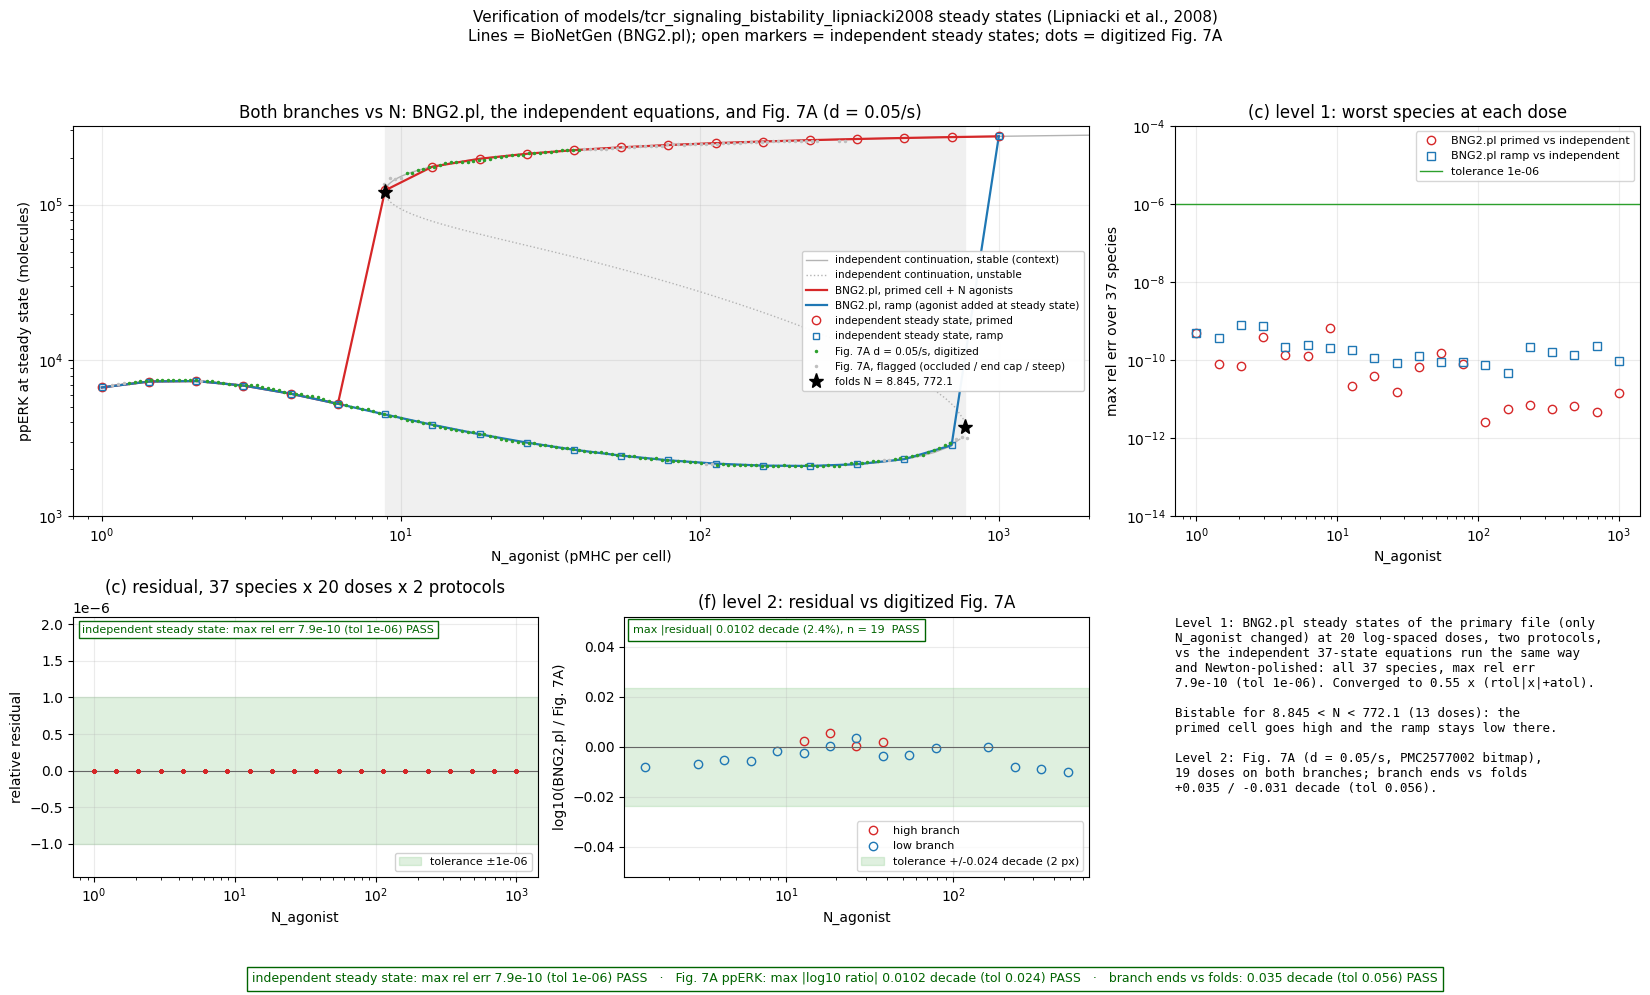

independent steady state: max rel err 7.9e-10 (tol 1e-06) PASS
Fig. 7A ppERK: max |log10 ratio| 0.0102 decade (tol 0.024) PASS
branch ends vs folds: 0.035 decade (tol 0.056) PASS


In [8]:
fig = plt.figure(figsize=(17, 10))
gs = fig.add_gridspec(2, 3, height_ratios=[1.5, 1.0])

ax = fig.add_subplot(gs[0, 0:2])
stable = c_growth < 0
seg = np.split(np.arange(len(curve)), np.flatnonzero(np.diff(stable.astype(int))) + 1)
for idx in seg:
    ax.plot(c_N[idx], c_erk[idx], ":" if not stable[idx[0]] else "-", color="0.7", lw=1.0,
            zorder=1)
ax.plot([], [], "-", color="0.7", lw=1, label="independent continuation, stable (context)")
ax.plot([], [], ":", color="0.7", lw=1, label="independent continuation, unstable")
ax.plot(DOSES, bng["primed"][:, 36], "-", color="C3", lw=1.6, label="BNG2.pl, primed cell + N agonists")
ax.plot(DOSES, bng["ramp"][:, 36], "-", color="C0", lw=1.6, label="BNG2.pl, ramp (agonist added at steady state)")
ax.plot(DOSES, ref["primed"][:, 36], "o", mfc="none", mec="C3", ms=6, ls="none",
        label="independent steady state, primed")
ax.plot(DOSES, ref["ramp"][:, 36], "s", mfc="none", mec="C0", ms=5, ls="none",
        label="independent steady state, ramp")
for branch, sub in dig.groupby("branch"):
    good = (sub.occluded == 0) & (sub.steep == 0) & (sub.end_cap == 0)
    ax.plot(sub.N_agonist[good], sub.ppERK_molecules[good], ".", color="tab:green", ms=3,
            label="Fig. 7A d = 0.05/s, digitized" if branch == "high" else None)
    ax.plot(sub.N_agonist[~good], sub.ppERK_molecules[~good], ".", color="0.75", ms=3,
            label="Fig. 7A, flagged (occluded / end cap / steep)" if branch == "high" else None)
ax.plot([N_LO, N_HI], [ERK_LO, ERK_HI], "*", color="k", ms=11, ls="none",
        label=f"folds N = {N_LO:.3f}, {N_HI:.1f}")
ax.axvspan(N_LO, N_HI, color="0.94", zorder=0)
ax.set(xscale="log", yscale="log", xlim=(0.8, 2000), ylim=(1000, 3.2e5), xlabel="N_agonist (pMHC per cell)",
       ylabel="ppERK at steady state (molecules)",
       title="Both branches vs N: BNG2.pl, the independent equations, and Fig. 7A (d = 0.05/s)")
ax.legend(fontsize=7.5, loc="center right", framealpha=0.95)
ax.grid(alpha=0.25)

ax = fig.add_subplot(gs[0, 2])
for p, c, mk in (("primed", "C3", "o"), ("ramp", "C0", "s")):
    ax.semilogx(DOSES, err_c[p].max(1), mk, mfc="none", mec=c, ls="none", label=f"BNG2.pl {p} vs independent")
ax.axhline(TOL_SS, color="tab:green", lw=1, label=f"tolerance {TOL_SS:g}")
ax.set(yscale="log", ylim=(1e-14, 1e-4), xlabel="N_agonist", ylabel="max rel err over 37 species",
       title="(c) level 1: worst species at each dose")
ax.legend(fontsize=8)
ax.grid(alpha=0.25)

metrics = []
ax = fig.add_subplot(gs[1, 0])
flat_n = np.repeat(np.concatenate([DOSES, DOSES]), 37)
model = np.concatenate([bng["primed"], bng["ramp"]]).ravel()
refv = np.concatenate([ref["primed"], ref["ramp"]]).ravel()
comp_c = Comparison("independent steady state", refv, tol=TOL_SS, floor=1.0)
residual_axis(ax, flat_n, model, comp_c, xlabel="N_agonist",
              title="(c) residual, 37 species x 20 doses x 2 protocols")
ax.set_xscale("log")
metrics.append(summarize(flat_n, model, comp_c))

ax = fig.add_subplot(gs[1, 1])
for branch, c in (("high", "C3"), ("low", "C0")):
    sub = level2[level2.branch == branch]
    ax.semilogx(sub.N, sub.decades, "o", mfc="none", mec=c, ls="none", label=f"{branch} branch")
ax.axhspan(-TOL_FIG, TOL_FIG, color="tab:green", alpha=0.15, label=f"tolerance +/-{TOL_FIG:.3f} decade (2 px)")
ax.axhline(0, color="0.4", lw=0.8)
ax.set(xlabel="N_agonist", ylabel="log10(BNG2.pl / Fig. 7A)", ylim=(-2.2 * TOL_FIG, 2.2 * TOL_FIG),
       title="(f) level 2: residual vs digitized Fig. 7A")
ax.text(0.02, 0.97, f"max |residual| {level2.decades.abs().max():.4f} decade "
        f"({100 * (10 ** level2.decades.abs().max() - 1):.1f}%), n = {len(level2)}  PASS",
        transform=ax.transAxes, va="top", fontsize=8, color="darkgreen",
        bbox={"fc": "white", "ec": "darkgreen"})
ax.legend(fontsize=8, loc="lower right")
ax.grid(alpha=0.25)
metrics.append(f"Fig. 7A ppERK: max |log10 ratio| {level2.decades.abs().max():.4f} decade "
               f"(tol {TOL_FIG:.3f}) PASS")
metrics.append(f"branch ends vs folds: {max(abs(e) for e in fold_err):.3f} decade "
               f"(tol {TOL_FOLD:.3f}) PASS")

ax = fig.add_subplot(gs[1, 2])
ax.axis("off")
ax.text(0.0, 1.0,
        "Level 1: BNG2.pl steady states of the primary file (only\n"
        "N_agonist changed) at 20 log-spaced doses, two protocols,\n"
        "vs the independent 37-state equations run the same way\n"
        "and Newton-polished: all 37 species, max rel err\n"
        f"{max(err_c['primed'].max(), err_c['ramp'].max()):.1e} (tol {TOL_SS:g}). Converged to "
        f"{changes.max():.2f} x (rtol|x|+atol).\n\n"
        f"Bistable for {N_LO:.3f} < N < {N_HI:.1f} ({bistable.sum()} doses): the\n"
        "primed cell goes high and the ramp stays low there.\n\n"
        "Level 2: Fig. 7A (d = 0.05/s, PMC2577002 bitmap),\n"
        f"{len(level2)} doses on both branches; branch ends vs folds\n"
        f"{fold_err[0]:+.3f} / {fold_err[1]:+.3f} decade (tol {TOL_FOLD:.3f}).",
        va="top", fontsize=9, family="monospace")

fig.suptitle("Verification of models/tcr_signaling_bistability_lipniacki2008 steady states "
             "(Lipniacki et al., 2008)\nLines = BioNetGen (BNG2.pl); open markers = independent "
             "steady states; dots = digitized Fig. 7A", fontsize=11)
fig.tight_layout(rect=(0, 0.05, 1, 0.95))
ok = verdict_footer(fig, metrics)
assert ok
fig.savefig("verify_lipniacki2008_steady_state.png", dpi=150, bbox_inches="tight")
plt.show()
for m in metrics:
    print(m if isinstance(m, str) else m.line())